#**Identificación y carga del dataset**

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bitext/training-dataset-for-chatbotsvirtual-assistants")

print("Path to dataset files:", path)

100%|██████████| 1.16M/1.16M [00:00<00:00, 2.42MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/versions/2


In [5]:
import os
for root, dirs, files in os.walk(path):
    print(f"\n📁 Carpeta: {root}")
    print(f"Subcarpetas: {len(dirs)}")
    print(f"Archivos: {len(files)}")

    # Mostrar algunos archivos de ejemplo
    for archivo in files[:5]:
        print("   ", archivo)


📁 Carpeta: /root/.cache/kagglehub/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/versions/2
Subcarpetas: 2
Archivos: 0

📁 Carpeta: /root/.cache/kagglehub/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/versions/2/Bitext_Sample_Customer_Service_Training_Dataset
Subcarpetas: 1
Archivos: 0

📁 Carpeta: /root/.cache/kagglehub/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/versions/2/Bitext_Sample_Customer_Service_Training_Dataset/Training
Subcarpetas: 0
Archivos: 4
    README.txt
    LICENSE.txt
    Bitext_Sample_Customer_Service_Training_Dataset.xlsx
    Bitext_Sample_Customer_Service_Training_Dataset.csv

📁 Carpeta: /root/.cache/kagglehub/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/versions/2/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample
Subcarpetas: 1
Archivos: 0

📁 Carpeta: /root/.cache/kagglehub/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/versions/2/20000-Utteranc

In [6]:
import shutil
import os

# Carpeta origen
origen = "/root/.cache/kagglehub/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/versions/2"

# Carpeta destino
destino = "/content/Actividad4JCP"

# Copiar toda la estructura de carpetas y archivos
shutil.copytree(origen, destino, dirs_exist_ok=True)

print("Archivos copiados correctamente a:", destino)

# Verificar estructura
for raiz, carpetas, archivos in os.walk(destino):
    nivel = raiz.replace(destino, "").count(os.sep)
    print("    " * nivel + "📁 " + os.path.basename(raiz))

    for archivo in archivos:
        print("    " * (nivel + 1) + "📄 " + archivo)

Archivos copiados correctamente a: /content/Actividad4JCP
📁 Actividad4JCP
    📁 Bitext_Sample_Customer_Service_Training_Dataset
        📁 Training
            📄 README.txt
            📄 LICENSE.txt
            📄 Bitext_Sample_Customer_Service_Training_Dataset.xlsx
            📄 Bitext_Sample_Customer_Service_Training_Dataset.csv
    📁 20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample
        📁 20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample
            📄 README.txt
            📄 LICENSE.txt
            📄 20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.xlsx
            📄 20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.csv


#**Exploracion del dataset**
Se realiza la exploracion del data set para conocer que datos se tienen, conteo de intenciones, categorias, nulos

In [7]:
import pandas as pd

#df = pd.read_csv("/content/Actividad4JCP/Bitext_Sample_Customer_Service_Training_Dataset/Training/Bitext_Sample_Customer_Service_Training_Dataset.csv")
df=pd.read_csv("/content/Actividad4JCP/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.csv")

df.head(10)


print("Dimensiones del dataset:")
print(df.shape)

print("\nValores nulos por columna:")
print(df.isnull().sum())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nNúmero de intenciones:")
print(df["intent"].nunique())

print("\nNúmero de categorías generales:")
print(df["category"].nunique())

print("\nDistribución por categoría general:")
print(df["category"].value_counts())

Dimensiones del dataset:
(21534, 4)

Valores nulos por columna:
flags        0
utterance    0
category     0
intent       0
dtype: int64

Registros duplicados:
12

Número de intenciones:
27

Número de categorías generales:
11

Distribución por categoría general:
category
PAYMENT             4636
ACCOUNT             4557
CONTACT             3081
INVOICES            2443
ORDER               2256
REFUNDS             1932
FEEDBACK            1326
DELIVERY             501
CANCELLATION_FEE     360
NEWSLETTER           236
SHIPPING             206
Name: count, dtype: int64


ANÁLISIS EXPLORATORIO DEL DATASET
Total de registros: 21,534
Total de columnas: 4
Categorías generales: 11
Intenciones específicas: 27
Valores nulos: 0
Registros duplicados: 12


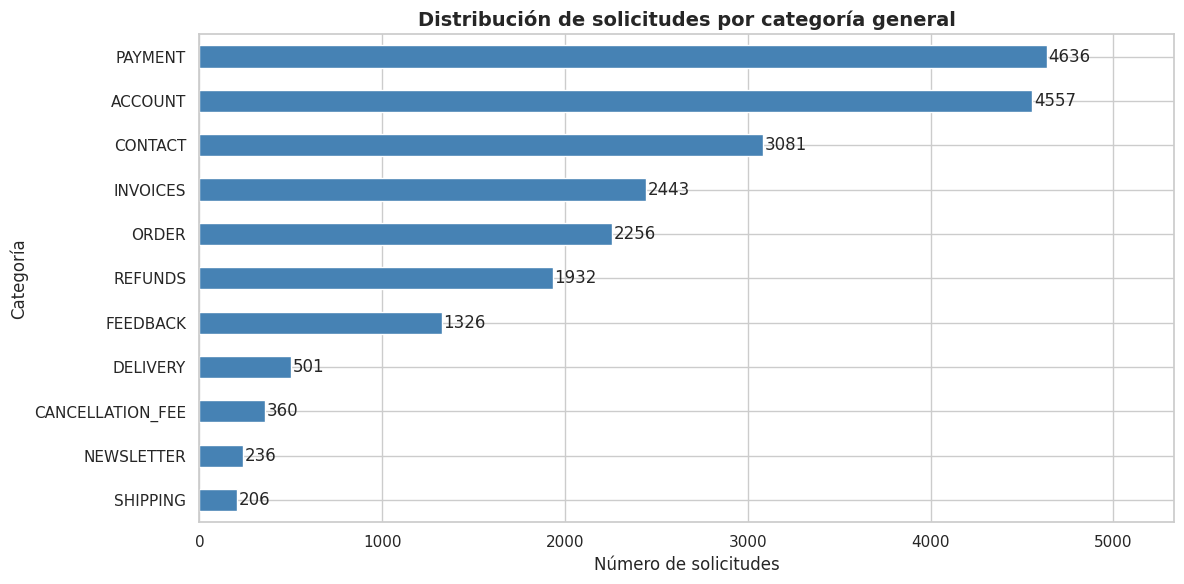

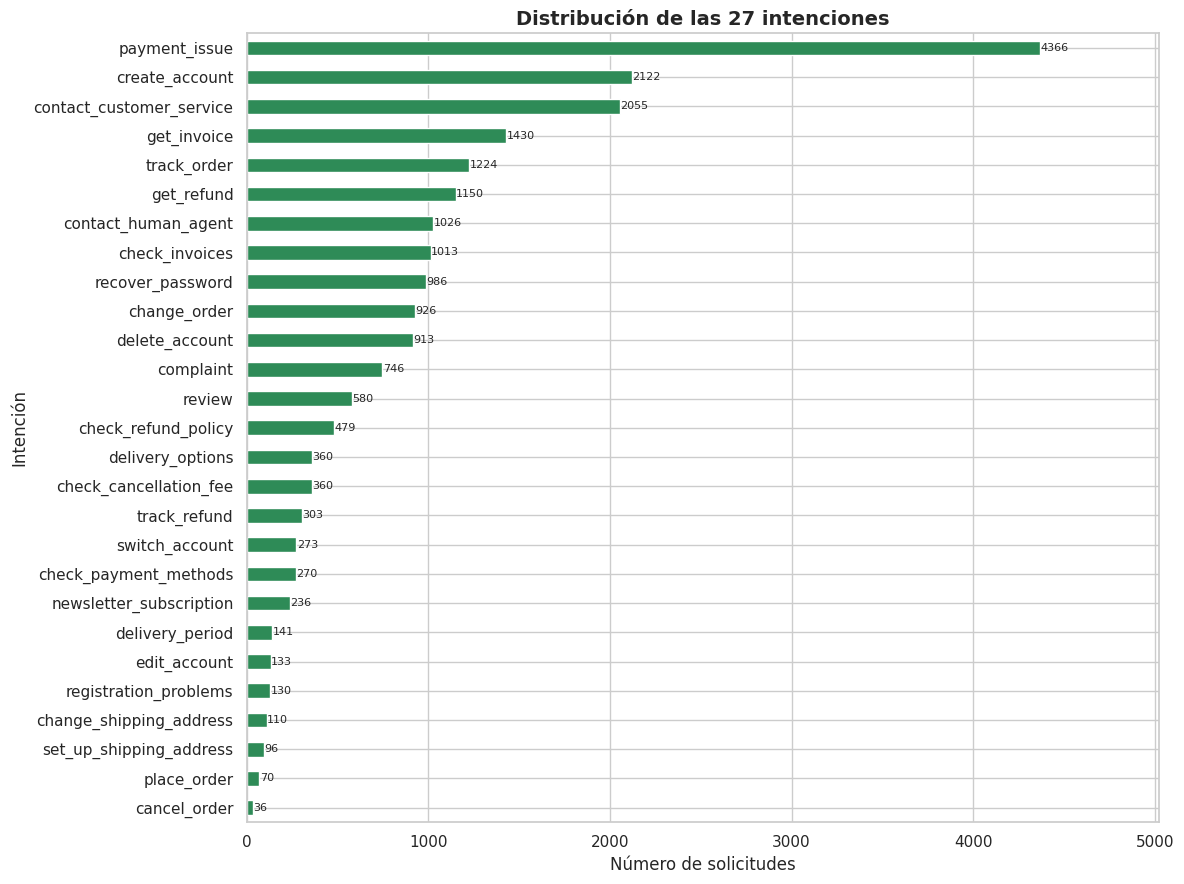


DISTRIBUCIÓN POR CATEGORÍA:


,Registros,Participación (%)
category,,
PAYMENT,4636,21.53
ACCOUNT,4557,21.16
CONTACT,3081,14.31
INVOICES,2443,11.34
ORDER,2256,10.48
REFUNDS,1932,8.97
FEEDBACK,1326,6.16
DELIVERY,501,2.33
CANCELLATION_FEE,360,1.67


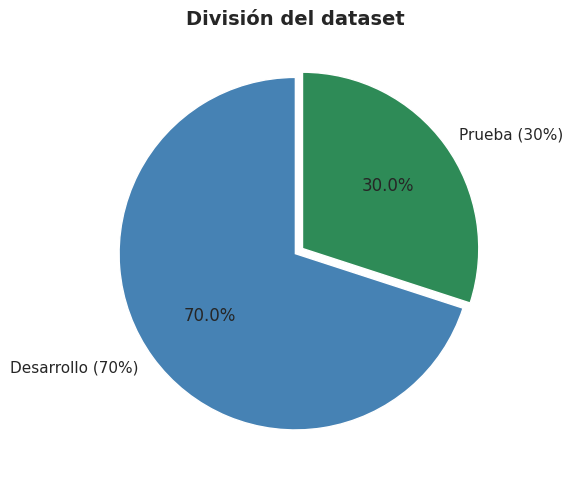

Registros para desarrollo: 15,073
Registros para prueba: 6,461


In [8]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. Resumen general del dataset
print("=" * 55)
print("ANÁLISIS EXPLORATORIO DEL DATASET")
print("=" * 55)
print(f"Total de registros: {len(df):,}")
print(f"Total de columnas: {df.shape[1]}")
print(f"Categorías generales: {df['category'].nunique()}")
print(f"Intenciones específicas: {df['intent'].nunique()}")
print(f"Valores nulos: {df.isnull().sum().sum()}")
print(f"Registros duplicados: {df.duplicated().sum()}")

# 2. Distribución por categoría general
categorias = df["category"].value_counts().sort_values()

plt.figure(figsize=(12, 6))
ax = categorias.plot(
    kind="barh",
    color="steelblue",
    edgecolor="white"
)

for i, valor in enumerate(categorias.values):
    ax.text(valor + 10, i, str(valor), va="center")

plt.title("Distribución de solicitudes por categoría general",
          fontsize=14, fontweight="bold")
plt.xlabel("Número de solicitudes")
plt.ylabel("Categoría")
plt.xlim(0, categorias.max() * 1.15)
plt.tight_layout()
plt.show()

# 3. Distribución de las 27 intenciones
intenciones = df["intent"].value_counts().sort_values()

plt.figure(figsize=(12, 9))
ax = intenciones.plot(
    kind="barh",
    color="seagreen",
    edgecolor="white"
)

for i, valor in enumerate(intenciones.values):
    ax.text(valor + 2, i, str(valor), va="center", fontsize=8)

plt.title("Distribución de las 27 intenciones",
          fontsize=14, fontweight="bold")
plt.xlabel("Número de solicitudes")
plt.ylabel("Intención")
plt.xlim(0, intenciones.max() * 1.15)
plt.tight_layout()
plt.show()

# 4. Distribución porcentual por categoría
resumen = pd.DataFrame({
    "Registros": df["category"].value_counts()
})
resumen["Participación (%)"] = (
    resumen["Registros"] / len(df) * 100
).round(2)

print("\nDISTRIBUCIÓN POR CATEGORÍA:")
display(resumen)

# 5. División de datos
total = len(df)
desarrollo = int(total * 0.70)
prueba = total - desarrollo

plt.figure(figsize=(7, 5))
plt.pie(
    [desarrollo, prueba],
    labels=["Desarrollo (70%)", "Prueba (30%)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "seagreen"],
    explode=(0, 0.05)
)
plt.title("División del dataset",
          fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Registros para desarrollo: {desarrollo:,}")
print(f"Registros para prueba: {prueba:,}")


#**Se identificaron 12 duplicados por lo que debemos de realizar la limpieza de datos**

In [9]:
# Conservar copia original
df_original = df.copy()

# Eliminar registros completamente duplicados
df_limpio = df.drop_duplicates().reset_index(drop=True)

# Resumen de limpieza
print("RESUMEN DE LIMPIEZA")
print("=" * 45)
print(f"Registros originales: {len(df_original):,}")
print(f"Registros eliminados: {len(df_original) - len(df_limpio):,}")
print(f"Registros finales: {len(df_limpio):,}")
print(f"Valores nulos: {df_limpio.isnull().sum().sum()}")

# Verificar duplicados en el texto, aunque
# las otras columnas sean diferentes
print("\nTextos repetidos en utterance:")
print(df_limpio.duplicated(subset=["utterance"]).sum())

# Distribución de intenciones
print("\nDISTRIBUCIÓN DE LAS 27 INTENCIONES")
display(
    df_limpio["intent"]
    .value_counts()
    .rename_axis("Intención")
    .reset_index(name="Registros")
)

RESUMEN DE LIMPIEZA
Registros originales: 21,534
Registros eliminados: 12
Registros finales: 21,522
Valores nulos: 0

Textos repetidos en utterance:
9

DISTRIBUCIÓN DE LAS 27 INTENCIONES


,Intención,Registros
0,payment_issue,4365
1,create_account,2122
2,contact_customer_service,2055
3,get_invoice,1421
4,track_order,1224
5,get_refund,1150
6,contact_human_agent,1026
7,check_invoices,1013
8,recover_password,986
9,change_order,924


In [10]:
#Validación de textos y etiquetas

# Cantidad de textos repetidos
repetidos = df_limpio.duplicated(
    subset=["utterance"]
).sum()

print("Textos repetidos:", repetidos)

# Detectar textos asociados a más de una intención
conflictos = (
    df_limpio.groupby("utterance")["intent"]
    .nunique()
)

conflictos = conflictos[conflictos > 1]

print("Textos con intenciones diferentes:", len(conflictos))

# Mostrar ejemplos si existen
if len(conflictos) > 0:
    ejemplos = df_limpio[
        df_limpio["utterance"].isin(
            conflictos.index
        )
    ]

    display(
        ejemplos[
            ["utterance", "category", "intent"]
        ].sort_values("utterance").head(20)
    )
else:
    print("No se encontraron conflictos de etiquetas.")


Textos repetidos: 9
Textos con intenciones diferentes: 0
No se encontraron conflictos de etiquetas.


In [11]:

# ==========================================================
# PASO 3 - DIVISIÓN ESTRATIFICADA DEL DATASET (70% / 30%)
# ==========================================================

import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Preparar dataset sin textos duplicados
# Partimos del DataFrame limpio del paso anterior

df_modelo = df_limpio.drop_duplicates(
    subset=["utterance"]
).reset_index(drop=True)

# 2. División estratificada
df_train, df_test = train_test_split(
    df_modelo,
    test_size=0.30,
    random_state=42,
    stratify=df_modelo["intent"]
)

# Reiniciar índices
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# 3. Mostrar resultados
print("=" * 55)
print("DIVISIÓN ESTRATIFICADA DEL DATASET")
print("=" * 55)

print(f"Total de registros: {len(df_modelo):,}")
print(f"Entrenamiento (70%): {len(df_train):,}")
print(f"Prueba (30%): {len(df_test):,}")

print("\nNúmero de intenciones:")
print("Entrenamiento:", df_train["intent"].nunique())
print("Prueba:", df_test["intent"].nunique())

# 4. Verificar ausencia de textos compartidos
textos_comunes = set(df_train["utterance"]).intersection(
    set(df_test["utterance"])
)

print("\nTextos compartidos entre conjuntos:",
      len(textos_comunes))

# 5. Comparación de distribución por intención
comparacion = pd.DataFrame({
    "Total": df_modelo["intent"].value_counts(),
    "Entrenamiento": df_train["intent"].value_counts(),
    "Prueba": df_test["intent"].value_counts()
}).fillna(0).astype(int)

comparacion["% Train"] = (
    comparacion["Entrenamiento"] /
    comparacion["Total"] * 100
).round(2)

comparacion["% Test"] = (
    comparacion["Prueba"] /
    comparacion["Total"] * 100
).round(2)

print("\nDISTRIBUCIÓN POR INTENCIÓN")
display(comparacion)

# 6. Verificaciones de integridad
assert len(df_train) + len(df_test) == len(df_modelo)
assert len(textos_comunes) == 0
assert df_train["intent"].nunique() == 27
assert df_test["intent"].nunique() == 27

print("\nValidaciones completadas correctamente.")


DIVISIÓN ESTRATIFICADA DEL DATASET
Total de registros: 21,513
Entrenamiento (70%): 15,059
Prueba (30%): 6,454

Número de intenciones:
Entrenamiento: 27
Prueba: 27

Textos compartidos entre conjuntos: 0

DISTRIBUCIÓN POR INTENCIÓN


,Total,Entrenamiento,Prueba,% Train,% Test
intent,,,,,
cancel_order,36,25,11,69.44,30.56
change_order,924,647,277,70.02,29.98
change_shipping_address,110,77,33,70.00,30.00
check_cancellation_fee,359,251,108,69.92,30.08
check_invoices,1013,709,304,69.99,30.01
check_payment_methods,270,189,81,70.00,30.00
check_refund_policy,476,333,143,69.96,30.04
complaint,746,522,224,69.97,30.03
contact_customer_service,2055,1439,616,70.02,29.98



Validaciones completadas correctamente.


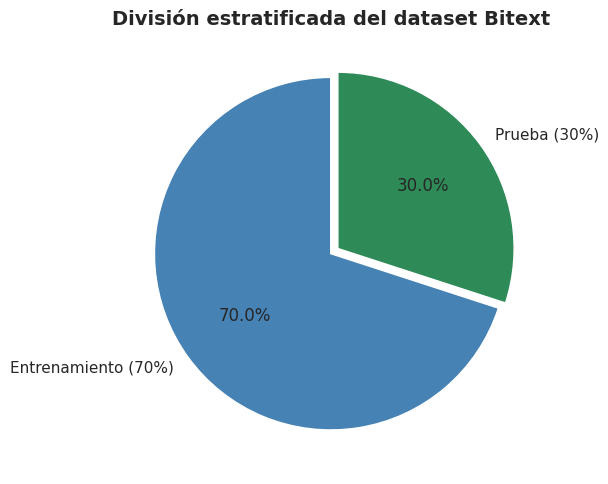

In [12]:

import matplotlib.pyplot as plt

valores = [len(df_train), len(df_test)]
etiquetas = ["Entrenamiento (70%)", "Prueba (30%)"]

plt.figure(figsize=(7, 5))

plt.pie(
    valores,
    labels=etiquetas,
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "seagreen"],
    explode=(0, 0.05)
)

plt.title(
    "División estratificada del dataset Bitext",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#**Ya realizada la exploracion de datos que obtuvimos de kaggle, seguimos con la preparacion del entonrno asi como la validacion del GPU**

In [13]:
#Verificacion del entorno, ya cambiamos "Entorno de Ejecución/Cambiar tipo de entorno de ejecución/GPU T4"

import torch
import platform

print("=" * 50)
print("CONFIGURACIÓN DEL ENTORNO")
print("=" * 50)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Memoria GPU (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        )
    )
else:
    print("No se detectó GPU.")
    print("Activa GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución.")


CONFIGURACIÓN DEL ENTORNO
Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: Tesla T4
Memoria GPU (GB): 14.56


#Instalacion de dependencias
Librería	Función
transformers	Cargar y ejecutar modelos preentrenados

accelerate	Facilitar la ejecución en GPU

huggingface_hub	Acceder a los modelos del Hub

sentencepiece y protobuf	Compatibilidad con tokenizadores


In [14]:
import importlib.util
import subprocess
import sys

paquetes = {
    "transformers": "transformers",
    "accelerate": "accelerate",
    "huggingface_hub": "huggingface_hub",
    "sentencepiece": "sentencepiece",
    "jedi":"jedi"
}

for modulo, paquete in paquetes.items():
    if importlib.util.find_spec(modulo) is None:
        print(f"Instalando {paquete}...")
        subprocess.check_call([
            sys.executable, "-m", "pip",
            "install", paquete
        ])
    else:
        print(f"{paquete}: disponible")

print("\nInstalación finalizada.")


transformers: disponible
accelerate: disponible
huggingface_hub: disponible
sentencepiece: disponible
Instalando jedi...

Instalación finalizada.


#Verificacion de librerias y entorno

In [15]:
import torch
import pandas as pd
import transformers
import sklearn
import huggingface_hub
import platform

print("=" * 55)
print("CONFIGURACIÓN DEL ENTORNO")
print("=" * 55)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nCONFIGURACIÓN GPU")

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    memoria = (
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3
    )
    print(f"Memoria disponible total: {memoria:.2f} GB")

print("\nVerificación completada.")
%pip check

CONFIGURACIÓN DEL ENTORNO
Python: 3.13.15
PyTorch: 2.11.0+cu130
Pandas: 2.2.3
Transformers: 5.18.0
Hugging Face Hub: 1.33.0
Scikit-learn: 1.6.1

CONFIGURACIÓN GPU
Dispositivo: cuda
GPU: Tesla T4
Memoria disponible total: 14.56 GB

Verificación completada.
No broken requirements found.


#Verificamos la conexion con Huggingface

In [16]:
from huggingface_hub import model_info

modelo = "facebook/bart-large-mnli"

try:
    info = model_info(modelo)

    print("Conexión exitosa con Hugging Face Hub")
    print("Modelo:", info.id)
    print("Revisión:", info.sha)

except Exception as e:
    print("Error de conexión:", str(e))


Conexión exitosa con Hugging Face Hub
Modelo: facebook/bart-large-mnli
Revisión: d7645e127eaf1aefc7862fd59a17a5aa8558b8ce


Verificamos nuestra conexion a HF con el token de lectura

In [19]:

from google.colab import userdata
from huggingface_hub import login, whoami

# Recuperar token desde los secretos de Colab
HF_TOKEN = userdata.get("FH_TOKEN")

# Autenticación
login(token=HF_TOKEN, add_to_git_credential=False)

# Verificar usuario autenticado
usuario = whoami()

print("=" * 50)
print("AUTENTICACIÓN HUGGING FACE")
print("=" * 50)
print("Usuario:", usuario["name"])
print("Estado: Autenticación correcta")

AUTENTICACIÓN HUGGING FACE
Usuario: al07182911
Estado: Autenticación correcta


In [20]:
from google.colab import files
import pandas as pd
df=pd.read_csv("/content/Actividad4JCP/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.csv")
print("\nDataset cargado correctamente")
print("Dimensiones:", df.shape)
print("Intenciones:", df["intent"].nunique())
print("Categorías:", df["category"].nunique())
display(df.head())


Dataset cargado correctamente
Dimensiones: (21534, 4)
Intenciones: 27
Categorías: 11


,flags,utterance,category,intent
0,BILC,"I don't have an online account, what do I have...",ACCOUNT,create_account
1,BILQZ,can you tell me if i can regisger two accounts...,ACCOUNT,create_account
2,BPLC,"I have no online account, open one, please",ACCOUNT,create_account
3,BIPLD,"could you ask an agent how to open an account,...",ACCOUNT,create_account
4,BLQC,"i want an online account, create one",ACCOUNT,create_account


In [21]:
from sklearn.model_selection import train_test_split

# Conservar copia original
df_original = df.copy()

# Eliminar duplicados completos
df_limpio = df.drop_duplicates().copy()

# Verificar etiquetas contradictorias
conflictos = (
    df_limpio.groupby("utterance")["intent"]
    .nunique()
)

assert (conflictos <= 1).all(), (
    "Existen textos con intenciones contradictorias."
)

# Eliminar textos repetidos
df_modelo = (
    df_limpio
    .drop_duplicates(subset=["utterance"])
    .reset_index(drop=True)
)

# División 70% / 30%
df_train, df_test = train_test_split(
    df_modelo,
    test_size=0.30,
    random_state=42,
    stratify=df_modelo["intent"]
)

df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Verificaciones
textos_comunes = (
    set(df_train["utterance"])
    & set(df_test["utterance"])
)

assert len(textos_comunes) == 0
assert df_train["intent"].nunique() == 27
assert df_test["intent"].nunique() == 27

print("=" * 55)
print("DATASET PREPARADO")
print("=" * 55)

print(f"Registros originales: {len(df_original):,}")
print(f"Registros finales: {len(df_modelo):,}")
print(f"Entrenamiento (70%): {len(df_train):,}")
print(f"Prueba (30%): {len(df_test):,}")
print(f"Textos compartidos: {len(textos_comunes)}")

print("\nDataset listo para evaluación.")


DATASET PREPARADO
Registros originales: 21,534
Registros finales: 21,513
Entrenamiento (70%): 15,059
Prueba (30%): 6,454
Textos compartidos: 0

Dataset listo para evaluación.


#Carga del primer modelo
**Modelo: DeBERTa-v3-small**


In [22]:
import torch
import time
from transformers import pipeline

modelo_1 = "cross-encoder/nli-deberta-v3-small"

print("=" * 55)
print("CARGANDO MODELO 1: DeBERTa-v3-small")
print("=" * 55)

inicio = time.perf_counter()

clasificador_1 = pipeline(
    task="zero-shot-classification",
    model=modelo_1,
    device=0 if torch.cuda.is_available() else -1
)

tiempo_carga = time.perf_counter() - inicio

print("Modelo cargado correctamente.")
print(f"Tiempo de carga: {tiempo_carga:.2f} segundos")

if torch.cuda.is_available():
    memoria = torch.cuda.memory_allocated() / 1024**3
    print(f"Memoria GPU utilizada: {memoria:.2f} GB")


CARGANDO MODELO 1: DeBERTa-v3-small


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

Modelo cargado correctamente.
Tiempo de carga: 8.32 segundos
Memoria GPU utilizada: 0.53 GB


In [23]:

# ==========================================================
# PRUEBA PILOTO DE CLASIFICACIÓN
# ==========================================================

# Obtener etiquetas del dataset
etiquetas = sorted(df_train["intent"].unique().tolist())

# Seleccionar una solicitud real del conjunto de desarrollo
ejemplo = df_train.iloc[0]["utterance"]
intencion_real = df_train.iloc[0]["intent"]

print("TEXTO DEL CLIENTE:")
print(ejemplo)

print("\nINTENCIÓN REAL:")
print(intencion_real)

# Convertir etiquetas técnicas en expresiones legibles
etiquetas_legibles = [
    etiqueta.replace("_", " ")
    for etiqueta in etiquetas
]

# Ejecutar clasificación zero-shot
inicio = time.perf_counter()

resultado = clasificador_1(
    ejemplo,
    candidate_labels=etiquetas_legibles,
    hypothesis_template="This customer request is about {}.",
    multi_label=False
)

# Sincronizar GPU para medir el tiempo completo
if torch.cuda.is_available():
    torch.cuda.synchronize()

latencia = time.perf_counter() - inicio

# Mostrar predicción
prediccion = resultado["labels"][0]
confianza = resultado["scores"][0]

print("\nRESULTADO DEL MODELO")
print("-" * 45)
print("Predicción:", prediccion)
print(f"Score del modelo: {confianza:.4f}")
print(f"Latencia: {latencia:.3f} segundos")

print("\nTOP 5 INTENCIONES")
for etiqueta, score in zip(
    resultado["labels"][:5],
    resultado["scores"][:5]
):
    print(f"{etiqueta}: {score:.4f}")


TEXTO DEL CLIENTE:
what's the mail to contact Customer Service?

INTENCIÓN REAL:
contact_customer_service

RESULTADO DEL MODELO
---------------------------------------------
Predicción: contact customer service
Score del modelo: 0.8116
Latencia: 2.099 segundos

TOP 5 INTENCIONES
contact customer service: 0.8116
delivery options: 0.0494
contact human agent: 0.0486
get invoice: 0.0100
create account: 0.0088


In [24]:

# ==========================================================
# EVALUACIÓN PILOTO DEL MODELO 1
# DeBERTa-v3-small - 100 solicitudes
# ==========================================================

import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Crear muestra piloto de 100 registros
# Garantizar al menos un ejemplo por intención
muestra_base = df_train.groupby("intent").sample(
    n=1, random_state=42
)

restantes = df_train.drop(muestra_base.index).sample(
    n=100 - len(muestra_base),
    random_state=42
)

df_piloto = pd.concat(
    [muestra_base, restantes]
).sample(frac=1, random_state=42).reset_index(drop=True)

# 2. Preparar etiquetas
etiquetas = sorted(df_train["intent"].unique().tolist())

etiquetas_legibles = [
    etiqueta.replace("_", " ")
    for etiqueta in etiquetas
]

mapa_etiquetas = {
    etiqueta.replace("_", " "): etiqueta
    for etiqueta in etiquetas
}

# 3. Evaluar solicitudes
predicciones = []
latencias = []

print("Iniciando evaluación piloto de 100 solicitudes...")

for i, fila in df_piloto.iterrows():

    inicio = time.perf_counter()

    resultado = clasificador_1(
        fila["utterance"],
        candidate_labels=etiquetas_legibles,
        hypothesis_template="This customer request is about {}.",
        multi_label=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latencia = time.perf_counter() - inicio

    prediccion = mapa_etiquetas[resultado["labels"][0]]

    predicciones.append(prediccion)
    latencias.append(latencia)

    if (i + 1) % 20 == 0:
        print(f"Procesados: {i + 1}/100")

# 4. Calcular métricas
y_real = df_piloto["intent"].tolist()
y_pred = predicciones

metricas_piloto = {
    "Accuracy": accuracy_score(y_real, y_pred),
    "Precision macro": precision_score(
        y_real, y_pred, average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_real, y_pred, average="macro", zero_division=0
    ),
    "F1 macro": f1_score(
        y_real, y_pred, average="macro", zero_division=0
    ),
    "Latencia media (s)": np.mean(latencias),
    "Latencia mediana (s)": np.median(latencias)
}

print("\nRESULTADOS DEL PILOTO")
print("=" * 50)

for metrica, valor in metricas_piloto.items():
    print(f"{metrica}: {valor:.4f}")

# 5. Guardar resultados para análisis
df_resultados_piloto = df_piloto.copy()
df_resultados_piloto["prediccion"] = predicciones
df_resultados_piloto["latencia_s"] = latencias
df_resultados_piloto["acierto"] = (
    df_resultados_piloto["intent"] ==
    df_resultados_piloto["prediccion"]
)

print("\nEvaluación piloto completada.")


Iniciando evaluación piloto de 100 solicitudes...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Procesados: 20/100
Procesados: 40/100
Procesados: 60/100
Procesados: 80/100
Procesados: 100/100

RESULTADOS DEL PILOTO
Accuracy: 0.6700
Precision macro: 0.5676
Recall macro: 0.5856
F1 macro: 0.5199
Latencia media (s): 0.4090
Latencia mediana (s): 0.3864

Evaluación piloto completada.


DESEMPEÑO POR INTENCIÓN


,precision,recall,f1-score,support
check_cancellation_fee,0.000,0.000,0.000,2.0
change_shipping_address,0.000,0.000,0.000,1.0
check_payment_methods,0.000,0.000,0.000,1.0
check_invoices,0.000,0.000,0.000,4.0
edit_account,0.000,0.000,0.000,2.0
set_up_shipping_address,0.000,0.000,0.000,1.0
track_order,0.000,0.000,0.000,3.0
check_refund_policy,1.000,0.200,0.333,5.0
delivery_period,0.250,0.500,0.333,2.0
get_refund,0.286,0.667,0.400,3.0


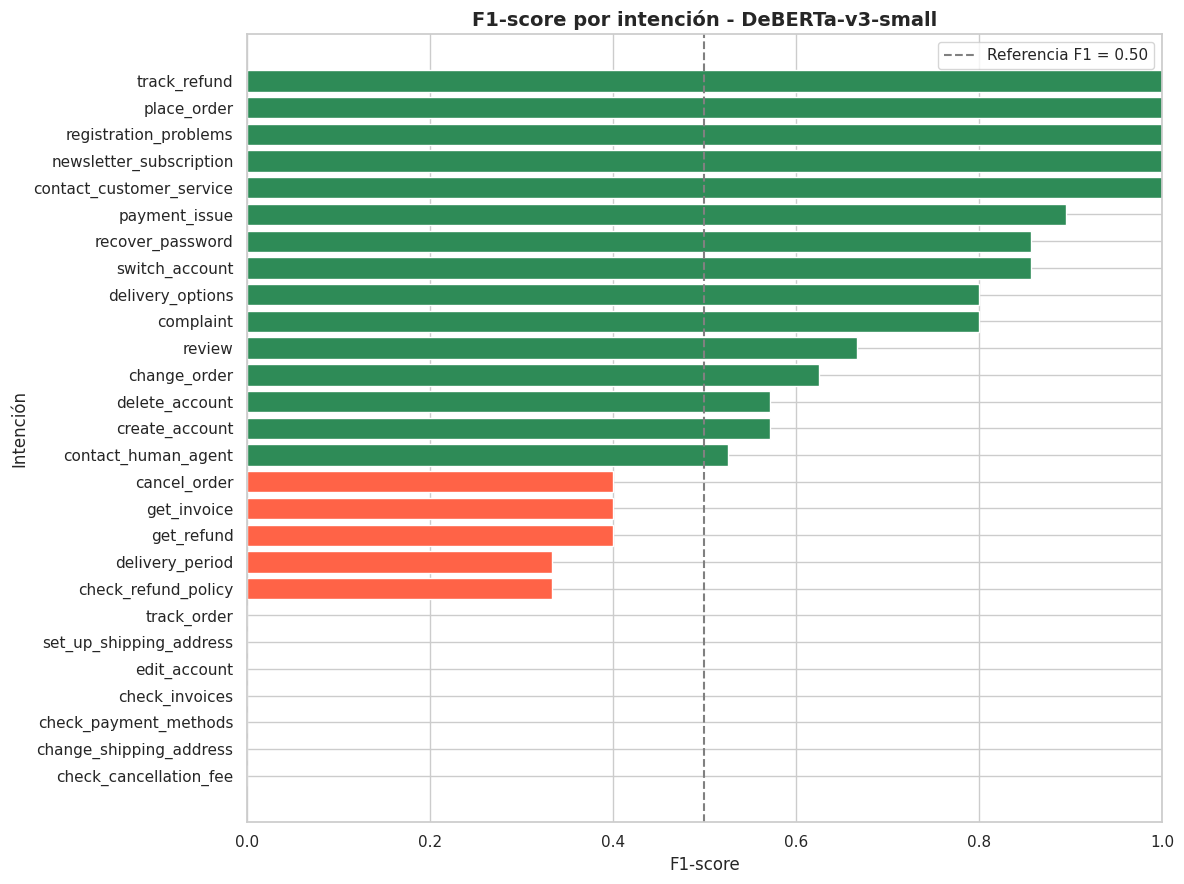


TOTAL DE ERRORES: 33

EJEMPLOS DE CLASIFICACIONES INCORRECTAS


,utterance,intent,prediccion
4,can you tell me about your refund policy?,check_refund_policy,get_refund
5,i wanna report an issue paying,payment_issue,complaint
8,"I don't have a profile, can you help me?",create_account,contact_human_agent
12,i want to know if i can download some bills,get_invoice,contact_human_agent
15,can I view my bill?,check_invoices,delivery_period
29,"i changed my mind, help me delete my online ac...",delete_account,change_order
33,tell me if my orders are out for delivery,track_order,delivery_period
34,"I want a user avcount, can you help me?",create_account,contact_human_agent
35,can I pay with Visa?,check_payment_methods,contact_human_agent
36,can u ask an agent if i can check my delivery?,track_order,review


In [25]:

# ==========================================================
# ANÁLISIS DE RESULTADOS POR INTENCIÓN
# MODELO 1: DeBERTa-v3-small
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# 1. Reporte de clasificación por intención
reporte = classification_report(
    df_resultados_piloto["intent"],
    df_resultados_piloto["prediccion"],
    labels=etiquetas,
    output_dict=True,
    zero_division=0
)

# Convertir a DataFrame
df_reporte = pd.DataFrame(reporte).T

# Seleccionar las 27 intenciones
df_intenciones = df_reporte.loc[
    etiquetas,
    ["precision", "recall", "f1-score", "support"]
].sort_values("f1-score", ascending=True)

print("DESEMPEÑO POR INTENCIÓN")
display(df_intenciones.round(3))

# 2. Visualizar F1-score por intención
plt.figure(figsize=(12, 9))

colores = [
    "tomato" if valor < 0.50 else "seagreen"
    for valor in df_intenciones["f1-score"]
]

plt.barh(
    df_intenciones.index,
    df_intenciones["f1-score"],
    color=colores
)

plt.axvline(
    x=0.50,
    color="gray",
    linestyle="--",
    label="Referencia F1 = 0.50"
)

plt.title(
    "F1-score por intención - DeBERTa-v3-small",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("F1-score")
plt.ylabel("Intención")
plt.xlim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Identificar errores de clasificación
errores = df_resultados_piloto[
    df_resultados_piloto["intent"] !=
    df_resultados_piloto["prediccion"]
]

print("\nTOTAL DE ERRORES:", len(errores))

print("\nEJEMPLOS DE CLASIFICACIONES INCORRECTAS")
display(
    errores[
        ["utterance", "intent", "prediccion"]
    ].head(15)
)


#Carga el segundo modelo
**Modelo: DeBERTa-v3-base**

In [26]:
import torch
import time
from transformers import pipeline

modelo_2 = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"

print("=" * 55)
print("CARGANDO MODELO 2: DeBERTa-v3-base")
print("=" * 55)

inicio = time.perf_counter()

clasificador_2 = pipeline(
    task="zero-shot-classification",
    model=modelo_2,
    device=0 if torch.cuda.is_available() else -1
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

tiempo_carga_2 = time.perf_counter() - inicio

print("\nModelo cargado correctamente.")
print(f"Tiempo de carga: {tiempo_carga_2:.2f} segundos")

if torch.cuda.is_available():
    memoria = torch.cuda.memory_allocated() / 1024**3
    print(f"Memoria GPU utilizada: {memoria:.2f} GB")

CARGANDO MODELO 2: DeBERTa-v3-base


config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.28k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]


Modelo cargado correctamente.
Tiempo de carga: 9.82 segundos
Memoria GPU utilizada: 0.90 GB


In [27]:
#Prueba

import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

predicciones_2 = []
latencias_2 = []

print("Iniciando evaluación del modelo 2...")
print(f"Solicitudes a evaluar: {len(df_piloto)}")

# Utilizar las mismas 100 solicitudes del modelo 1
for i, fila in df_piloto.iterrows():

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    resultado = clasificador_2(
        fila["utterance"],
        candidate_labels=etiquetas_legibles,
        hypothesis_template="This customer request is about {}.",
        multi_label=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latencia = time.perf_counter() - inicio

    prediccion = mapa_etiquetas[resultado["labels"][0]]

    predicciones_2.append(prediccion)
    latencias_2.append(latencia)

    if (i + 1) % 20 == 0:
        print(f"Procesados: {i + 1}/{len(df_piloto)}")

# Calcular métricas
y_real = df_piloto["intent"].tolist()

metricas_modelo_2 = {
    "Accuracy": accuracy_score(y_real, predicciones_2),
    "Precision macro": precision_score(
        y_real, predicciones_2,
        labels=etiquetas,
        average="macro",
        zero_division=0
    ),
    "Recall macro": recall_score(
        y_real, predicciones_2,
        labels=etiquetas,
        average="macro",
        zero_division=0
    ),
    "F1 macro": f1_score(
        y_real, predicciones_2,
        labels=etiquetas,
        average="macro",
        zero_division=0
    ),
    "Latencia media (s)": np.mean(latencias_2),
    "Latencia mediana (s)": np.median(latencias_2)
}

print("\nRESULTADOS DEL MODELO 2")
print("=" * 50)

for metrica, valor in metricas_modelo_2.items():
    print(f"{metrica}: {valor:.4f}")

# Guardar resultados
df_resultados_modelo_2 = df_piloto.copy()

df_resultados_modelo_2["prediccion"] = predicciones_2
df_resultados_modelo_2["latencia_s"] = latencias_2

df_resultados_modelo_2["acierto"] = (
    df_resultados_modelo_2["intent"] ==
    df_resultados_modelo_2["prediccion"]
)

print("\nEvaluación del modelo 2 completada.")


Iniciando evaluación del modelo 2...
Solicitudes a evaluar: 100
Procesados: 20/100
Procesados: 40/100
Procesados: 60/100
Procesados: 80/100
Procesados: 100/100

RESULTADOS DEL MODELO 2
Accuracy: 0.7100
Precision macro: 0.6104
Recall macro: 0.6093
F1 macro: 0.5743
Latencia media (s): 0.8347
Latencia mediana (s): 0.7312

Evaluación del modelo 2 completada.


In [28]:

# ==========================================================
# COMPARACIÓN PILOTO DE LOS MODELOS 1 Y 2
# ==========================================================

comparacion_modelos = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1 macro",
        "Latencia media (s)",
        "Latencia mediana (s)"
    ],
    "DeBERTa-v3-small": [
        metricas_piloto["Accuracy"],
        metricas_piloto["Precision macro"],
        metricas_piloto["Recall macro"],
        metricas_piloto["F1 macro"],
        metricas_piloto["Latencia media (s)"],
        metricas_piloto["Latencia mediana (s)"]
    ],
    "DeBERTa-v3-base": [
        metricas_modelo_2["Accuracy"],
        metricas_modelo_2["Precision macro"],
        metricas_modelo_2["Recall macro"],
        metricas_modelo_2["F1 macro"],
        metricas_modelo_2["Latencia media (s)"],
        metricas_modelo_2["Latencia mediana (s)"]
    ]
})

print("COMPARACIÓN PRELIMINAR DE MODELOS")
display(comparacion_modelos.round(4))


COMPARACIÓN PRELIMINAR DE MODELOS


,Métrica,DeBERTa-v3-small,DeBERTa-v3-base
0,Accuracy,0.6700,0.7100
1,Precision macro,0.5676,0.6104
2,Recall macro,0.5856,0.6093
3,F1 macro,0.5199,0.5743
4,Latencia media (s),0.4090,0.8347
5,Latencia mediana (s),0.3864,0.7312


#Carga de tercer modelo
**Modelo: BART-large-MNLI**

In [29]:
import torch
import time
import gc
from transformers import pipeline

# Liberar modelos anteriores de la GPU
del clasificador_1
del clasificador_2

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

# Cargar tercer modelo
modelo_3 = "facebook/bart-large-mnli"

print("=" * 55)
print("CARGANDO MODELO 3: BART-large-MNLI")
print("=" * 55)

inicio = time.perf_counter()

clasificador_3 = pipeline(
    task="zero-shot-classification",
    model=modelo_3,
    device=0 if torch.cuda.is_available() else -1
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

tiempo_carga_3 = time.perf_counter() - inicio

print("\nModelo cargado correctamente.")
print(f"Tiempo de carga: {tiempo_carga_3:.2f} segundos")

if torch.cuda.is_available():
    memoria = torch.cuda.memory_allocated() / 1024**3
    print(f"Memoria GPU asignada: {memoria:.2f} GB")


CARGANDO MODELO 3: BART-large-MNLI


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]


Modelo cargado correctamente.
Tiempo de carga: 17.22 segundos
Memoria GPU asignada: 1.53 GB


In [30]:

# ==========================================================
# EVALUACIÓN PILOTO DEL MODELO 3
# BART-large-MNLI - 100 solicitudes
# ==========================================================

import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

predicciones_3 = []
latencias_3 = []

print("=" * 55)
print("EVALUACIÓN PILOTO: BART-large-MNLI")
print("=" * 55)

print(f"Solicitudes: {len(df_piloto)}")
print(f"Intenciones: {len(etiquetas_legibles)}")

# Utilizar exactamente el mismo conjunto piloto
for i, fila in df_piloto.iterrows():

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    resultado = clasificador_3(
        fila["utterance"],
        candidate_labels=etiquetas_legibles,
        hypothesis_template="This customer request is about {}.",
        multi_label=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latencia = time.perf_counter() - inicio

    prediccion = mapa_etiquetas[resultado["labels"][0]]

    predicciones_3.append(prediccion)
    latencias_3.append(latencia)

    if (i + 1) % 20 == 0:
        print(f"Procesados: {i + 1}/{len(df_piloto)}")

# Calcular métricas
y_real = df_piloto["intent"].tolist()

metricas_modelo_3 = {
    "Accuracy": accuracy_score(y_real, predicciones_3),

    "Precision macro": precision_score(
        y_real,
        predicciones_3,
        labels=etiquetas,
        average="macro",
        zero_division=0
    ),

    "Recall macro": recall_score(
        y_real,
        predicciones_3,
        labels=etiquetas,
        average="macro",
        zero_division=0
    ),

    "F1 macro": f1_score(
        y_real,
        predicciones_3,
        labels=etiquetas,
        average="macro",
        zero_division=0
    ),

    "Latencia media (s)": np.mean(latencias_3),
    "Latencia mediana (s)": np.median(latencias_3)
}

print("\nRESULTADOS DEL MODELO 3")
print("=" * 55)

for metrica, valor in metricas_modelo_3.items():
    print(f"{metrica}: {valor:.4f}")

# Guardar resultados detallados
df_resultados_modelo_3 = df_piloto.copy()

df_resultados_modelo_3["prediccion"] = predicciones_3
df_resultados_modelo_3["latencia_s"] = latencias_3

df_resultados_modelo_3["acierto"] = (
    df_resultados_modelo_3["intent"] ==
    df_resultados_modelo_3["prediccion"]
)

print("\nEvaluación piloto del modelo 3 completada.")


EVALUACIÓN PILOTO: BART-large-MNLI
Solicitudes: 100
Intenciones: 27
Procesados: 20/100
Procesados: 40/100
Procesados: 60/100
Procesados: 80/100
Procesados: 100/100

RESULTADOS DEL MODELO 3
Accuracy: 0.8000
Precision macro: 0.7629
Recall macro: 0.7377
F1 macro: 0.7144
Latencia media (s): 0.6417
Latencia mediana (s): 0.6039

Evaluación piloto del modelo 3 completada.


In [31]:

# ==========================================================
# COMPARACIÓN DE LOS TRES MODELOS PREENTRENADOS
# ==========================================================

comparacion_final_piloto = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1 macro",
        "Latencia media (s)",
        "Latencia mediana (s)"
    ],
    "DeBERTa-small": [
        metricas_piloto["Accuracy"],
        metricas_piloto["Precision macro"],
        metricas_piloto["Recall macro"],
        metricas_piloto["F1 macro"],
        metricas_piloto["Latencia media (s)"],
        metricas_piloto["Latencia mediana (s)"]
    ],
    "DeBERTa-base": [
        metricas_modelo_2["Accuracy"],
        metricas_modelo_2["Precision macro"],
        metricas_modelo_2["Recall macro"],
        metricas_modelo_2["F1 macro"],
        metricas_modelo_2["Latencia media (s)"],
        metricas_modelo_2["Latencia mediana (s)"]
    ],
    "BART-large-MNLI": [
        metricas_modelo_3["Accuracy"],
        metricas_modelo_3["Precision macro"],
        metricas_modelo_3["Recall macro"],
        metricas_modelo_3["F1 macro"],
        metricas_modelo_3["Latencia media (s)"],
        metricas_modelo_3["Latencia mediana (s)"]
    ]
})

print("=" * 65)
print("COMPARACIÓN PILOTO DE LOS TRES MODELOS")
print("=" * 65)

display(comparacion_final_piloto.round(4))


COMPARACIÓN PILOTO DE LOS TRES MODELOS


,Métrica,DeBERTa-small,DeBERTa-base,BART-large-MNLI
0,Accuracy,0.6700,0.7100,0.8000
1,Precision macro,0.5676,0.6104,0.7629
2,Recall macro,0.5856,0.6093,0.7377
3,F1 macro,0.5199,0.5743,0.7144
4,Latencia media (s),0.4090,0.8347,0.6417
5,Latencia mediana (s),0.3864,0.7312,0.6039


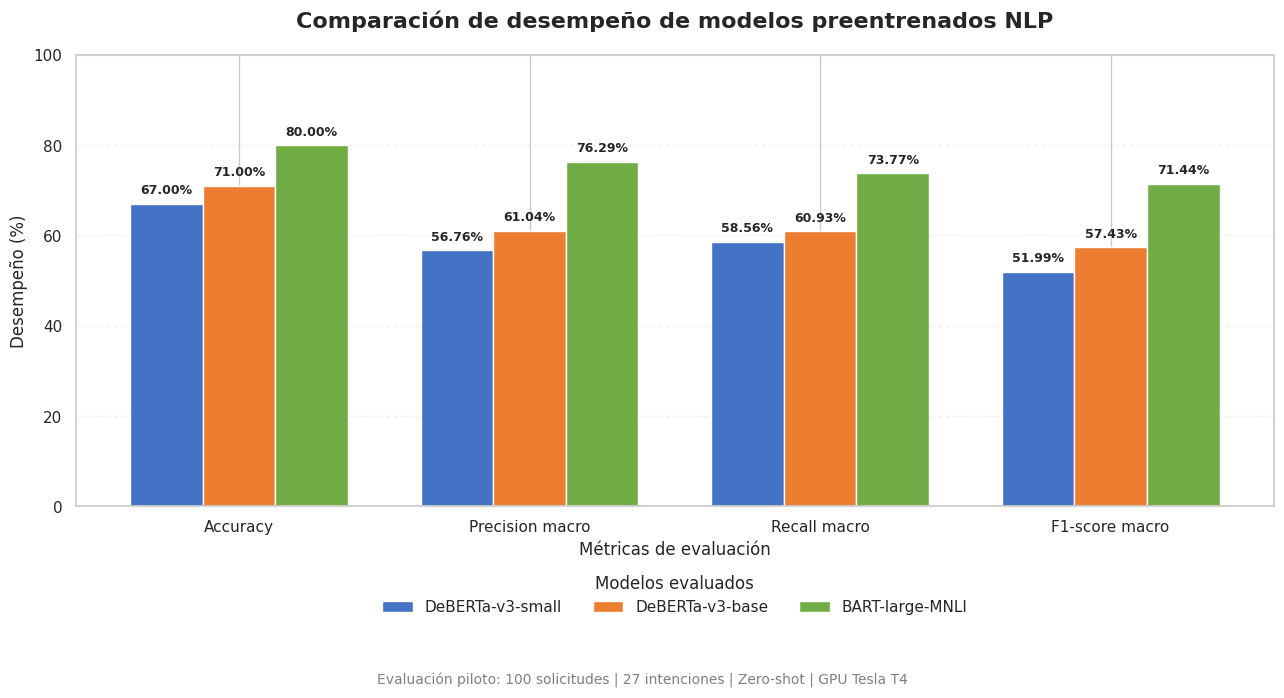

Gráfica guardada: comparacion_metricas_modelos.png


In [32]:

# ==========================================================
# COMPARACIÓN DE MÉTRICAS DE LOS TRES MODELOS
# Proyecto: Clasificación de solicitudes mediante NLP
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Resultados reales de la evaluación piloto
metricas = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1-score macro"
    ],
    "DeBERTa-v3-small": [0.6700, 0.5676, 0.5856, 0.5199],
    "DeBERTa-v3-base": [0.7100, 0.6104, 0.6093, 0.5743],
    "BART-large-MNLI": [0.8000, 0.7629, 0.7377, 0.7144]
})

# 2. Configuración del gráfico
modelos = [
    "DeBERTa-v3-small",
    "DeBERTa-v3-base",
    "BART-large-MNLI"
]

colores = ["#4472C4", "#ED7D31", "#70AD47"]

x = np.arange(len(metricas))
ancho = 0.25

fig, ax = plt.subplots(figsize=(13, 7))

# 3. Dibujar barras
for i, modelo in enumerate(modelos):

    valores = metricas[modelo].values * 100

    barras = ax.bar(
        x + (i - 1) * ancho,
        valores,
        ancho,
        label=modelo,
        color=colores[i]
    )

    # Etiquetas de porcentaje
    for barra in barras:
        altura = barra.get_height()

        ax.annotate(
            f"{altura:.2f}%",
            xy=(
                barra.get_x() + barra.get_width() / 2,
                altura
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )


ax.set_title(
    "Comparación de desempeño de modelos preentrenados NLP",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Desempeño (%)", fontsize=12)
ax.set_xlabel("Métricas de evaluación", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(metricas["Métrica"], fontsize=11)

ax.set_ylim(0, 100)

ax.legend(
    title="Modelos evaluados",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)


fig.text(
    0.5, 0.01,
    "Evaluación piloto: 100 solicitudes | "
    "27 intenciones | Zero-shot | GPU Tesla T4",
    ha="center",
    fontsize=10,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])


plt.savefig(
    "comparacion_metricas_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada: comparacion_metricas_modelos.png")


#Definicion del entorno de ejecucion

In [33]:

# ==========================================================
# GENERAR REQUIREMENTS.TXT
# Proyecto: Clasificación de solicitudes mediante NLP
# ==========================================================

from importlib.metadata import version
from pathlib import Path

# Dependencias utilizadas en el proyecto
paquetes = [
    "torch",
    "transformers",
    "accelerate",
    "huggingface_hub",
    "sentencepiece",
    "scikit-learn",
    "pandas",
    "numpy",
    "matplotlib"
]

dependencias = []

for paquete in paquetes:
    try:
        version_instalada = version(paquete)
        dependencias.append(
            f"{paquete}=={version_instalada}"
        )
        print(f"{paquete}: {version_instalada}")
    except Exception:
        print(f"{paquete}: no instalado")

# Guardar archivo
contenido = "\n".join(dependencias) + "\n"

Path("/content/requirements.txt").write_text(
    contenido,
    encoding="utf-8"
)

print("\nArchivo requirements.txt generado.")
print("\nCONTENIDO:")
print(contenido)


torch: 2.11.0+cu130
transformers: 5.18.0
accelerate: 1.15.0
huggingface_hub: 1.33.0
sentencepiece: 0.2.2
scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.1.3
matplotlib: 3.10.0

Archivo requirements.txt generado.

CONTENIDO:
torch==2.11.0+cu130
transformers==5.18.0
accelerate==1.15.0
huggingface_hub==1.33.0
sentencepiece==0.2.2
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0



In [34]:
from google.colab import files

files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>